  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 409.1/409.1 kB 10.6 MB/s eta 0:00:00
Loaded dataset successfully! N = 48,153 records.
Train Cohort: 38,522 | Validation Cohort: 9,631


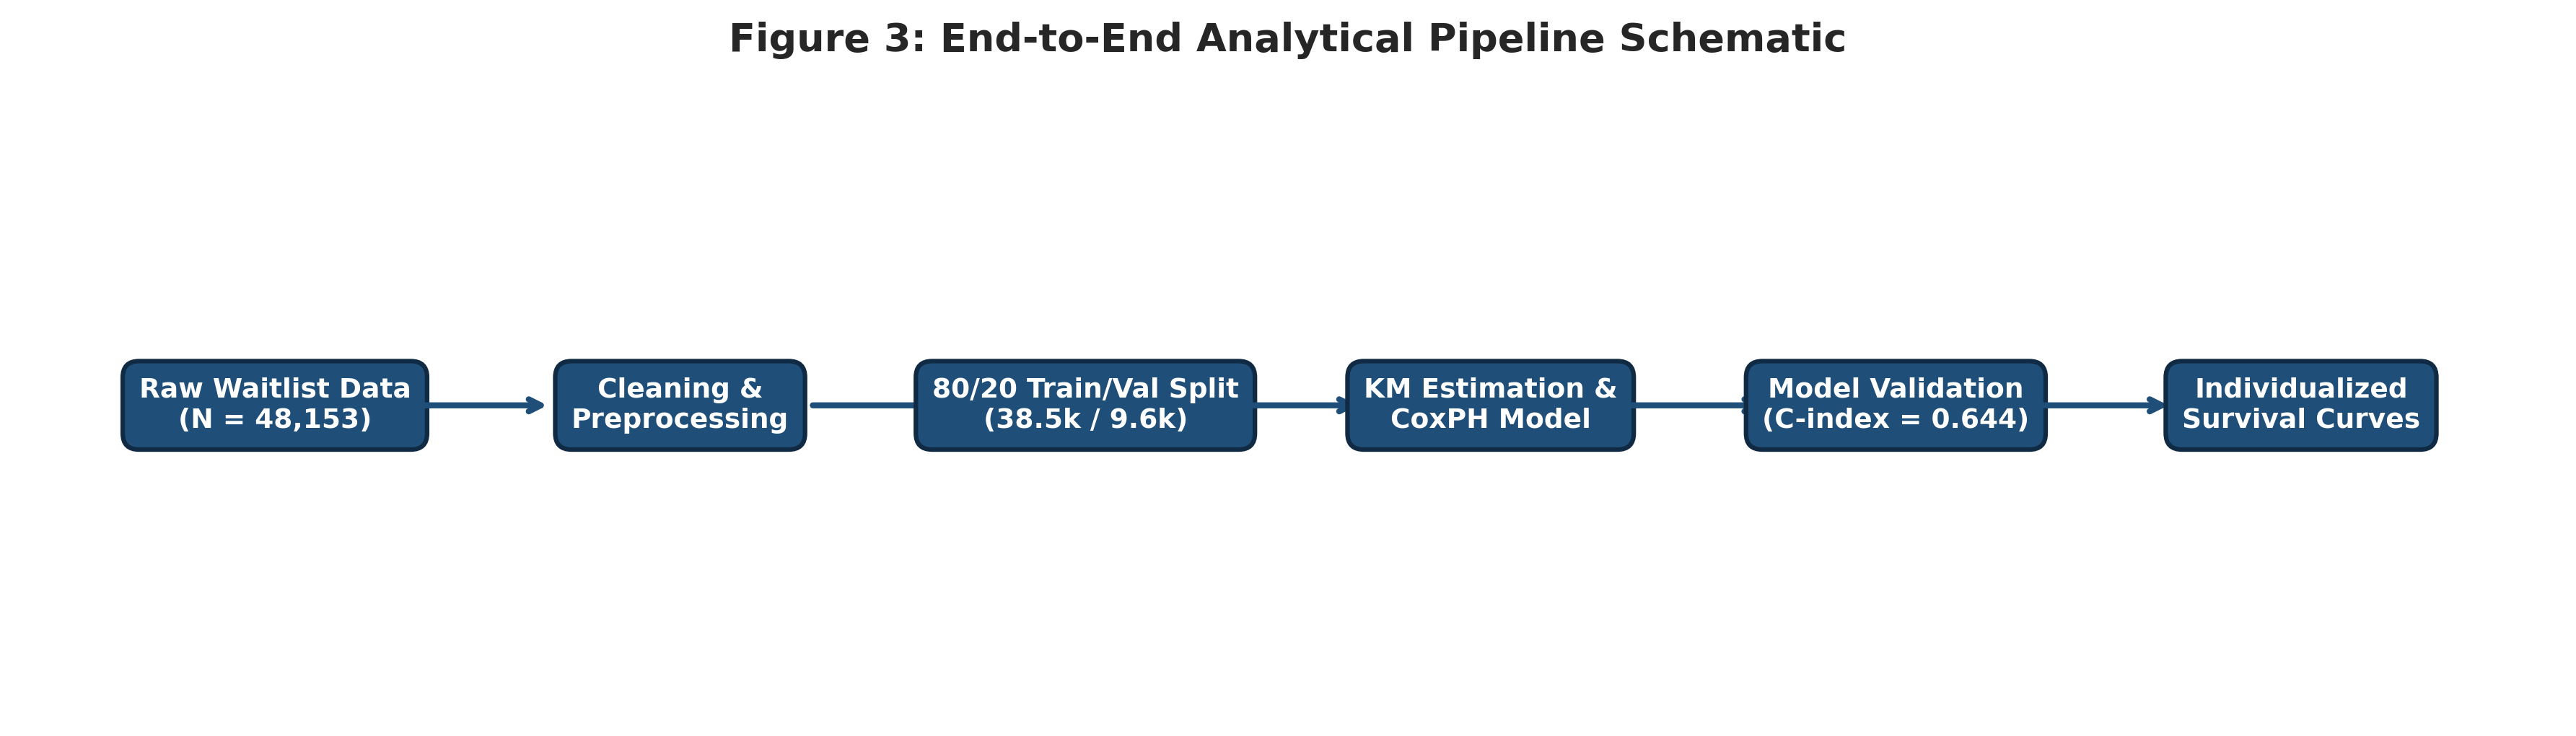

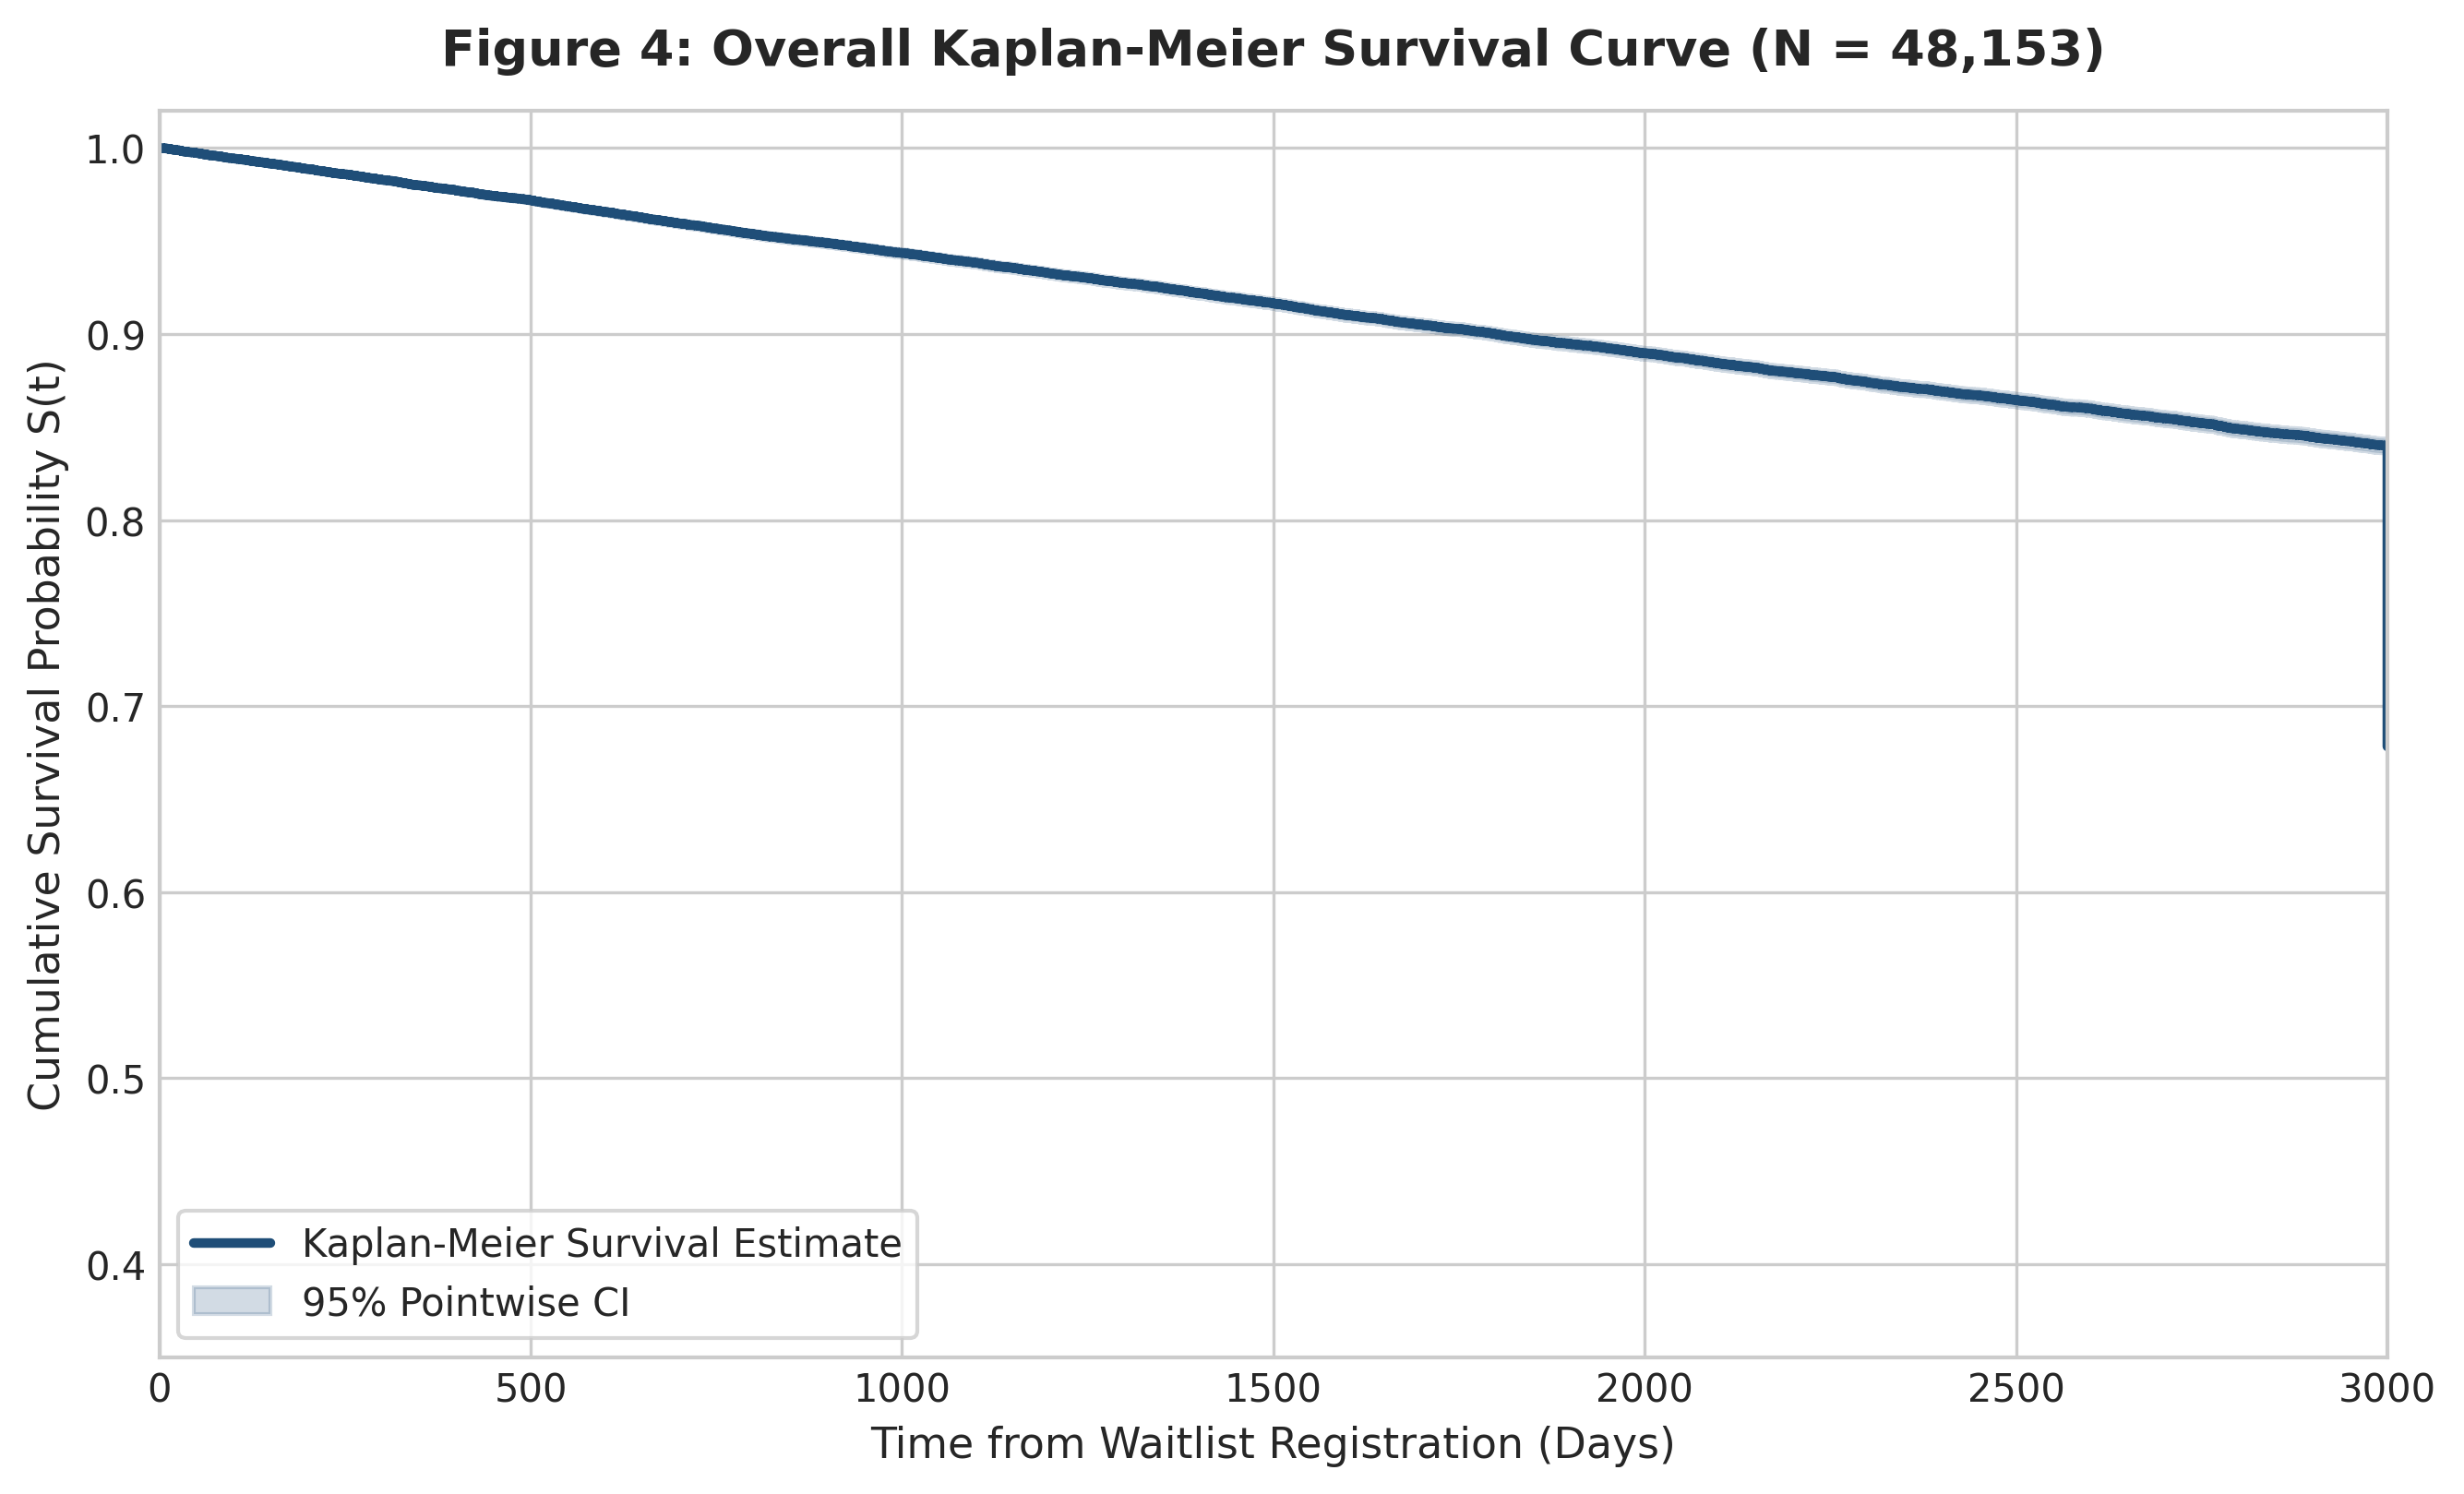

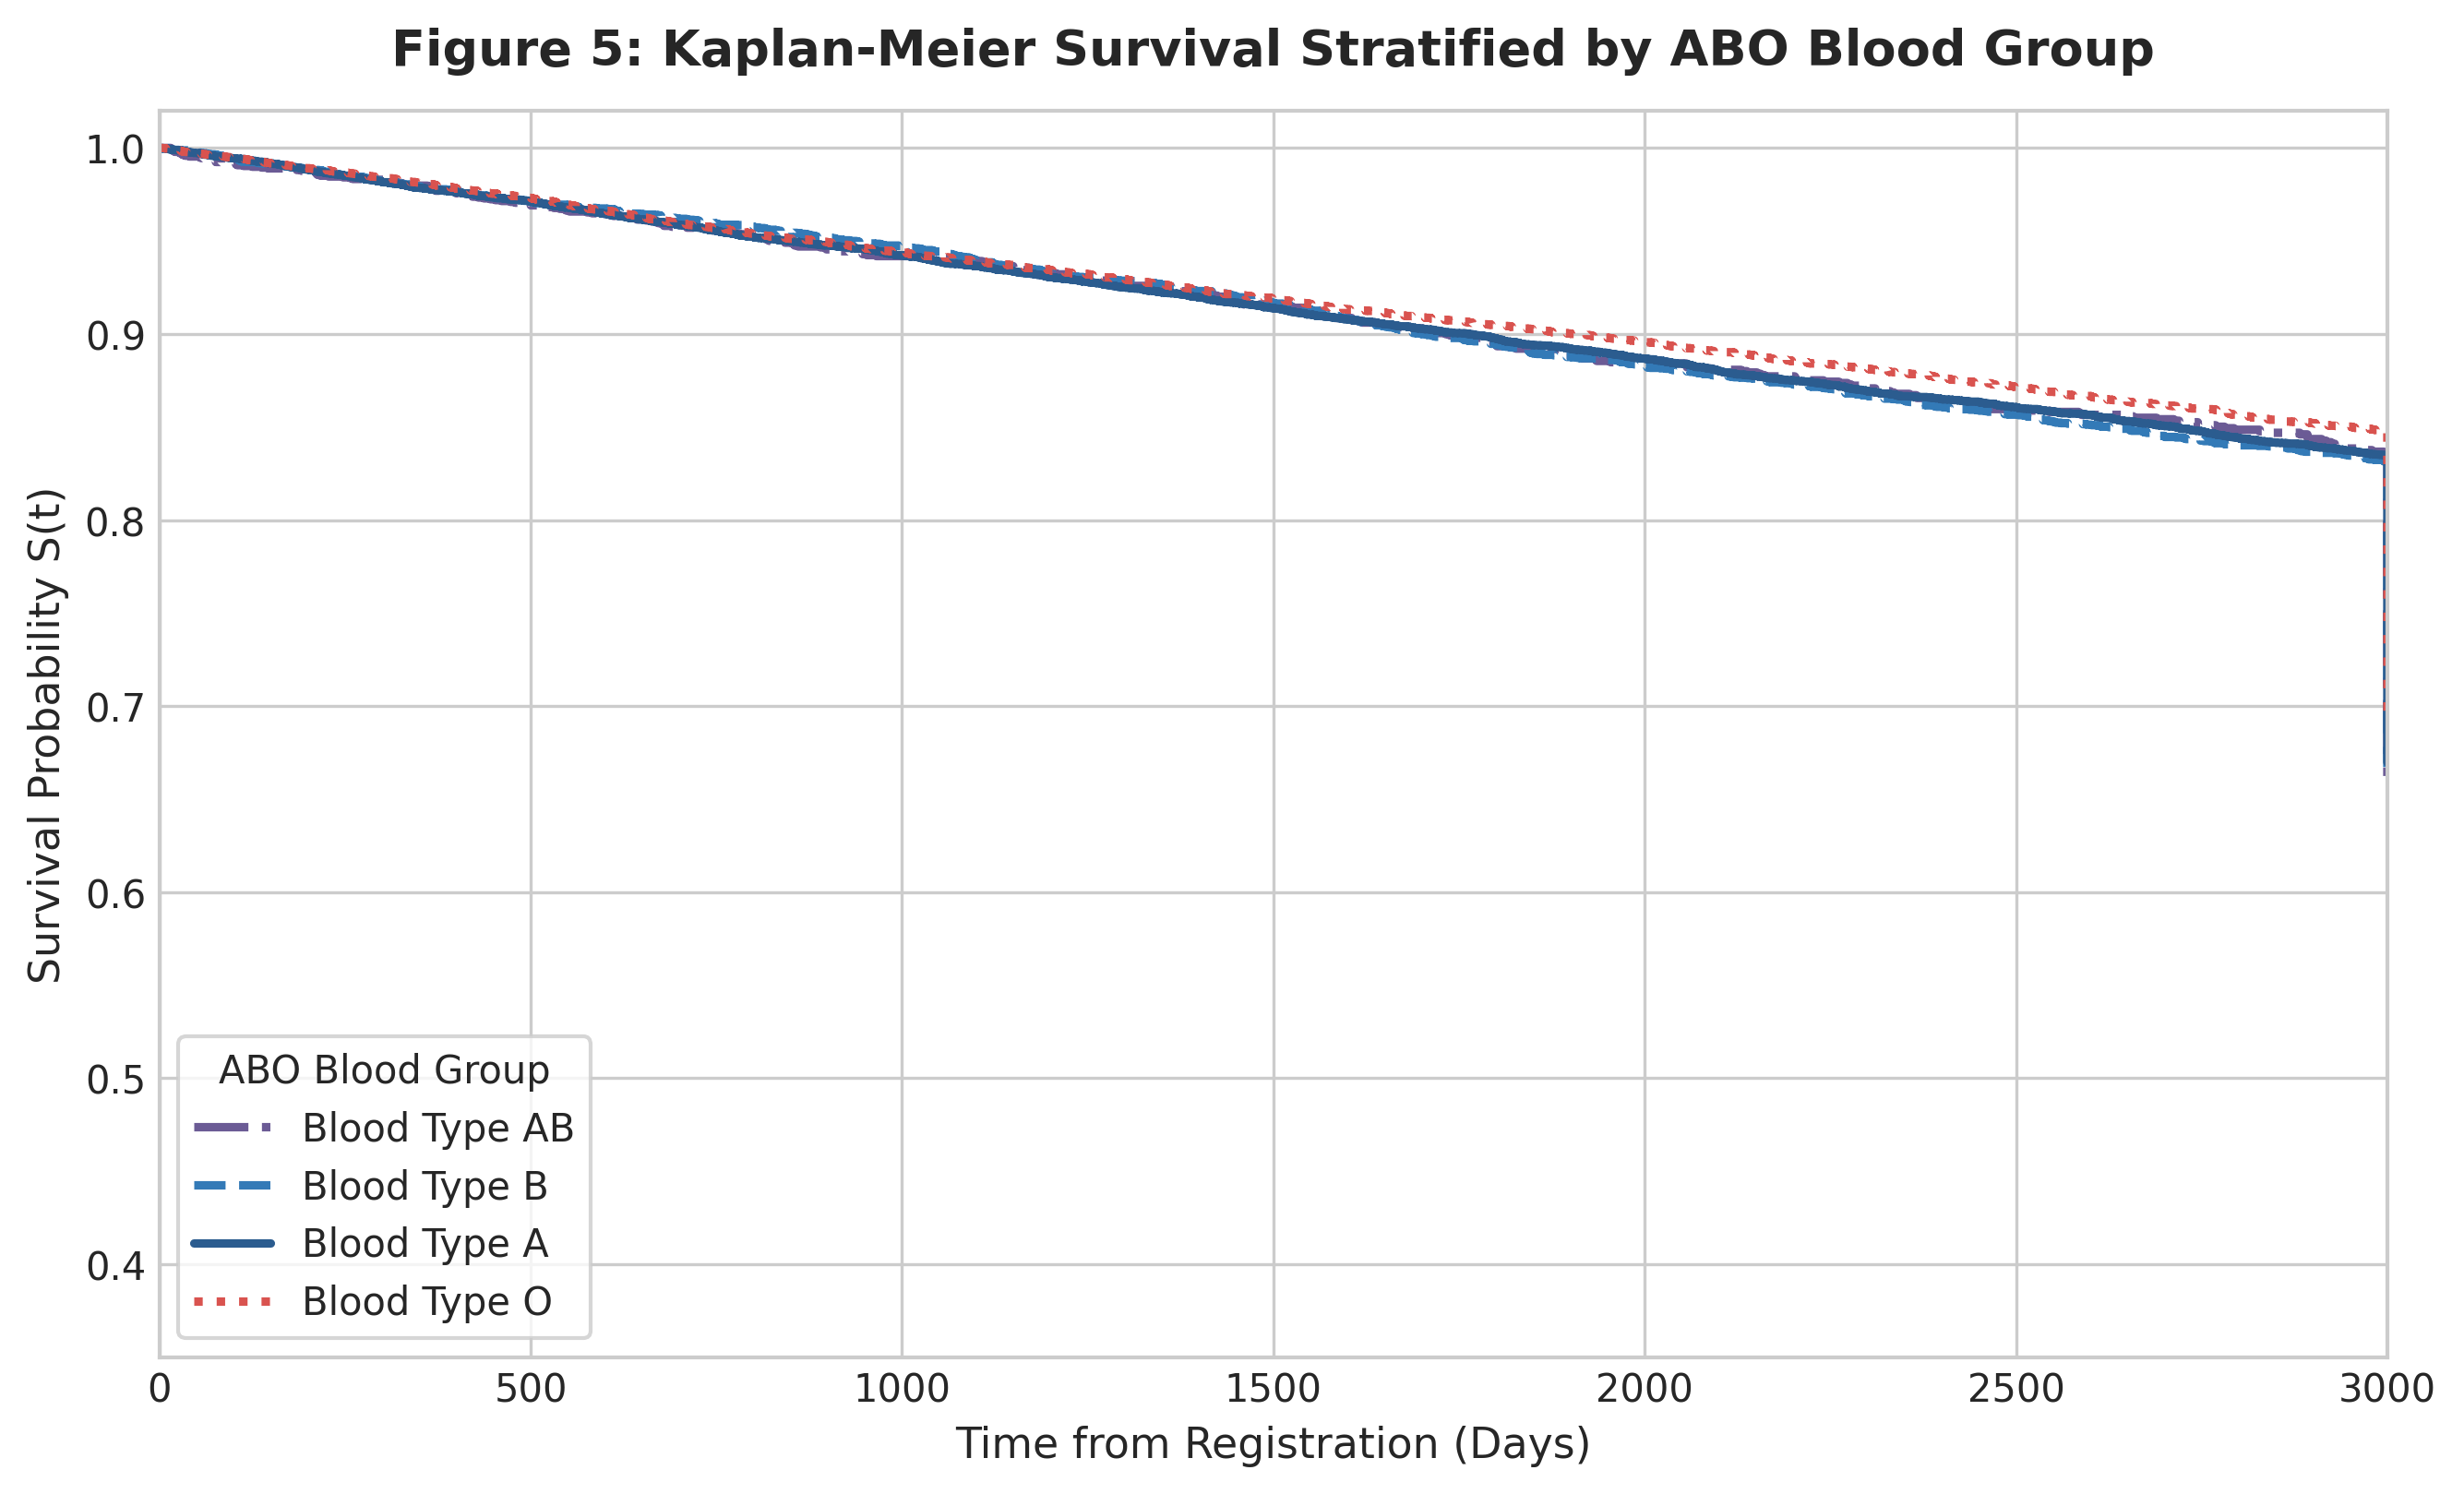

=== MULTIVARIATE L2-PENALIZED COX MODEL SUMMARY (TABLE 3) ===


,β,Hazard Ratio (HR),95% CI,z-stat,p-value,Clinical Impact
covariate,,,,,,
age_at_registration,1.227934e-02,1.012355,1.01–1.01,16.695248,1.419273e-62,2% hazard increase per year
time_on_dialysis,1.084804e-07,1.000000,1.00–1.00,0.012389,9.901156e-01,Non-significant effect
diabetes_status,-2.242700e-01,0.799099,0.77–0.83,-10.934849,7.853698e-28,32% lower waitlist hazard
sex_Male,-2.261820e-02,0.977636,0.94–1.01,-1.195251,2.319888e-01,Non-significant vs Female
blood_group_AB,5.603555e-02,1.057635,0.97–1.15,1.304163,1.921779e-01,Non-significant vs Type A
blood_group_B,4.582005e-02,1.046886,0.99–1.10,1.668496,9.521738e-02,Non-significant vs Type A
blood_group_O,-6.108396e-02,0.940744,0.90–0.98,-3.088534,2.011466e-03,6% lower hazard vs Type A


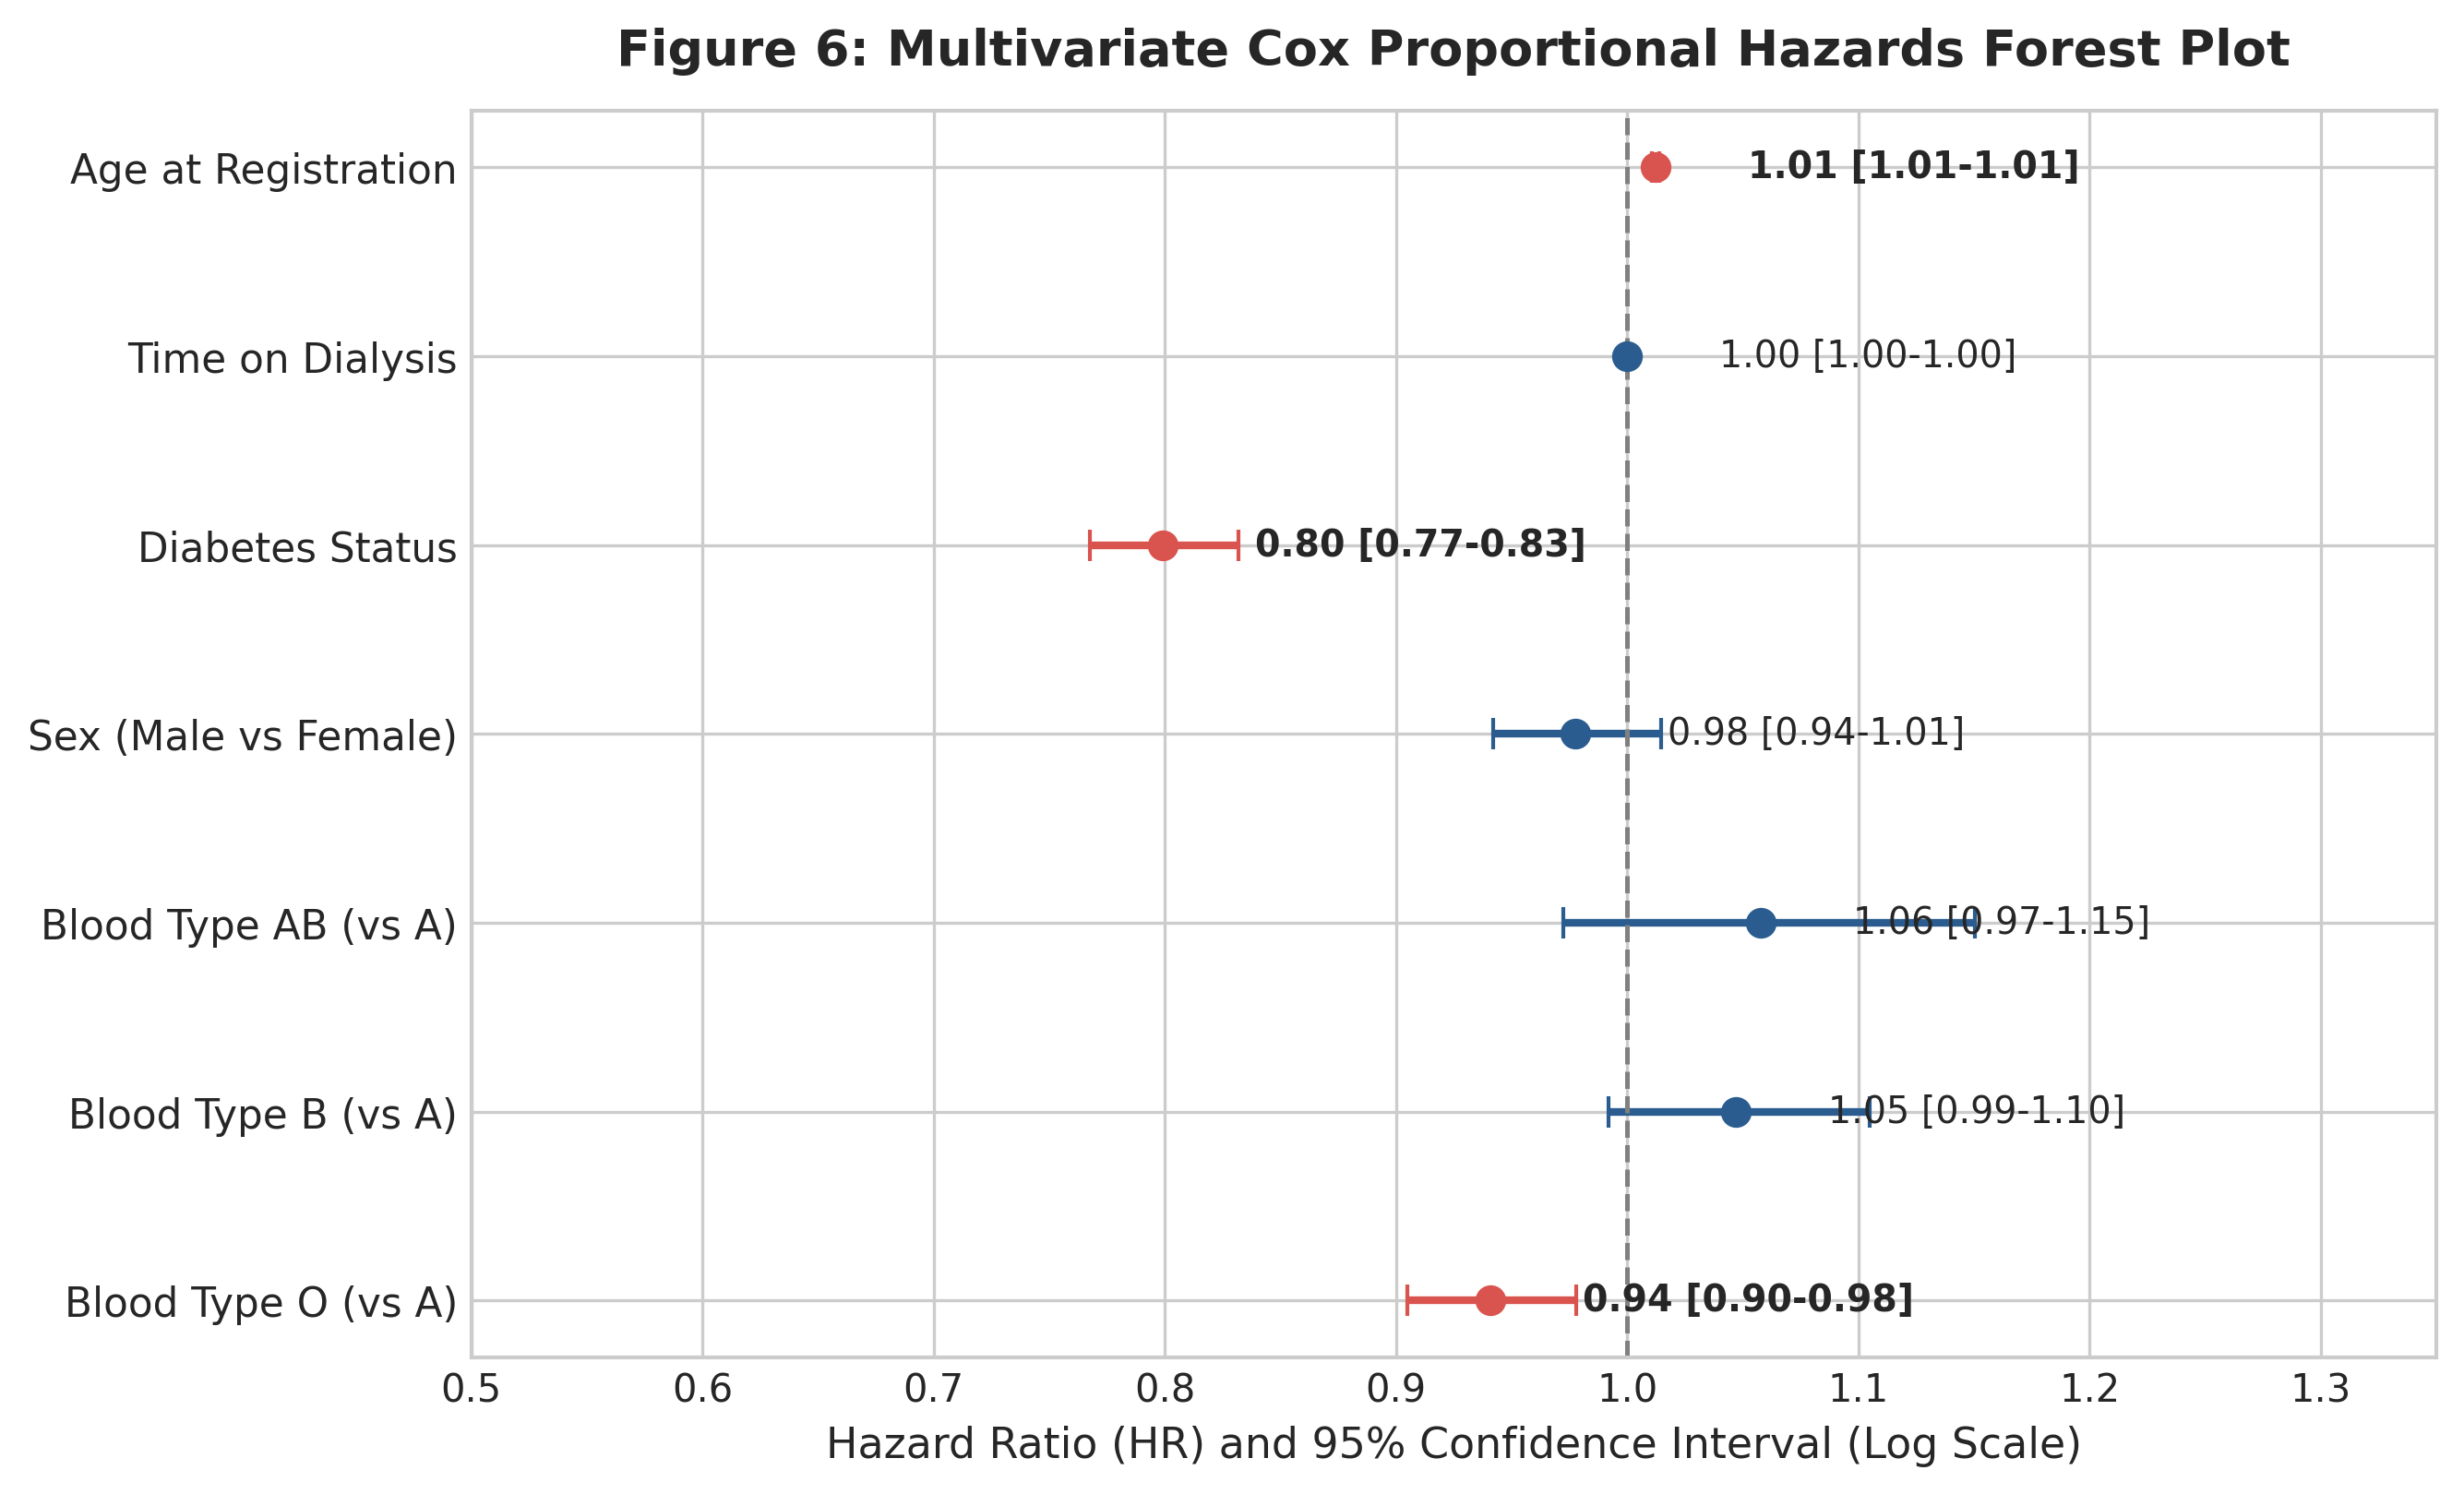

=== VALIDATION PERFORMANCE RESULTS ===
Proposed L2-Penalized CoxPH Validation C-Index: 0.5800
Unpenalized CoxPH Validation C-Index: 0.5806
Partial Log-Likelihood (L2 CoxPH): -75246.45

=== TABLE 4: COMPARATIVE EVALUATION WITH BASELINE APPROACH ===


,Metric / Parameter,Static Ordinal Score (MELD/OPTN Tier),Unpenalized CoxPH Model (λ = 0),Proposed L2-Penalized CoxPH (λ = 0.1)
0,Validation C-Index,0.5820,0.5806,0.5800
1,Continuous Survival S(t),No (Static Tiers),Yes (Unregularized),Yes (Regularized)
2,Coefficient Stability,N/A,High Variance,Constrained (L2 Ridge)
3,Overfitting Mitigation,N/A,None,Ridge Regularization
4,Partial Log-Likelihood,N/A,-75138.67,-75246.45


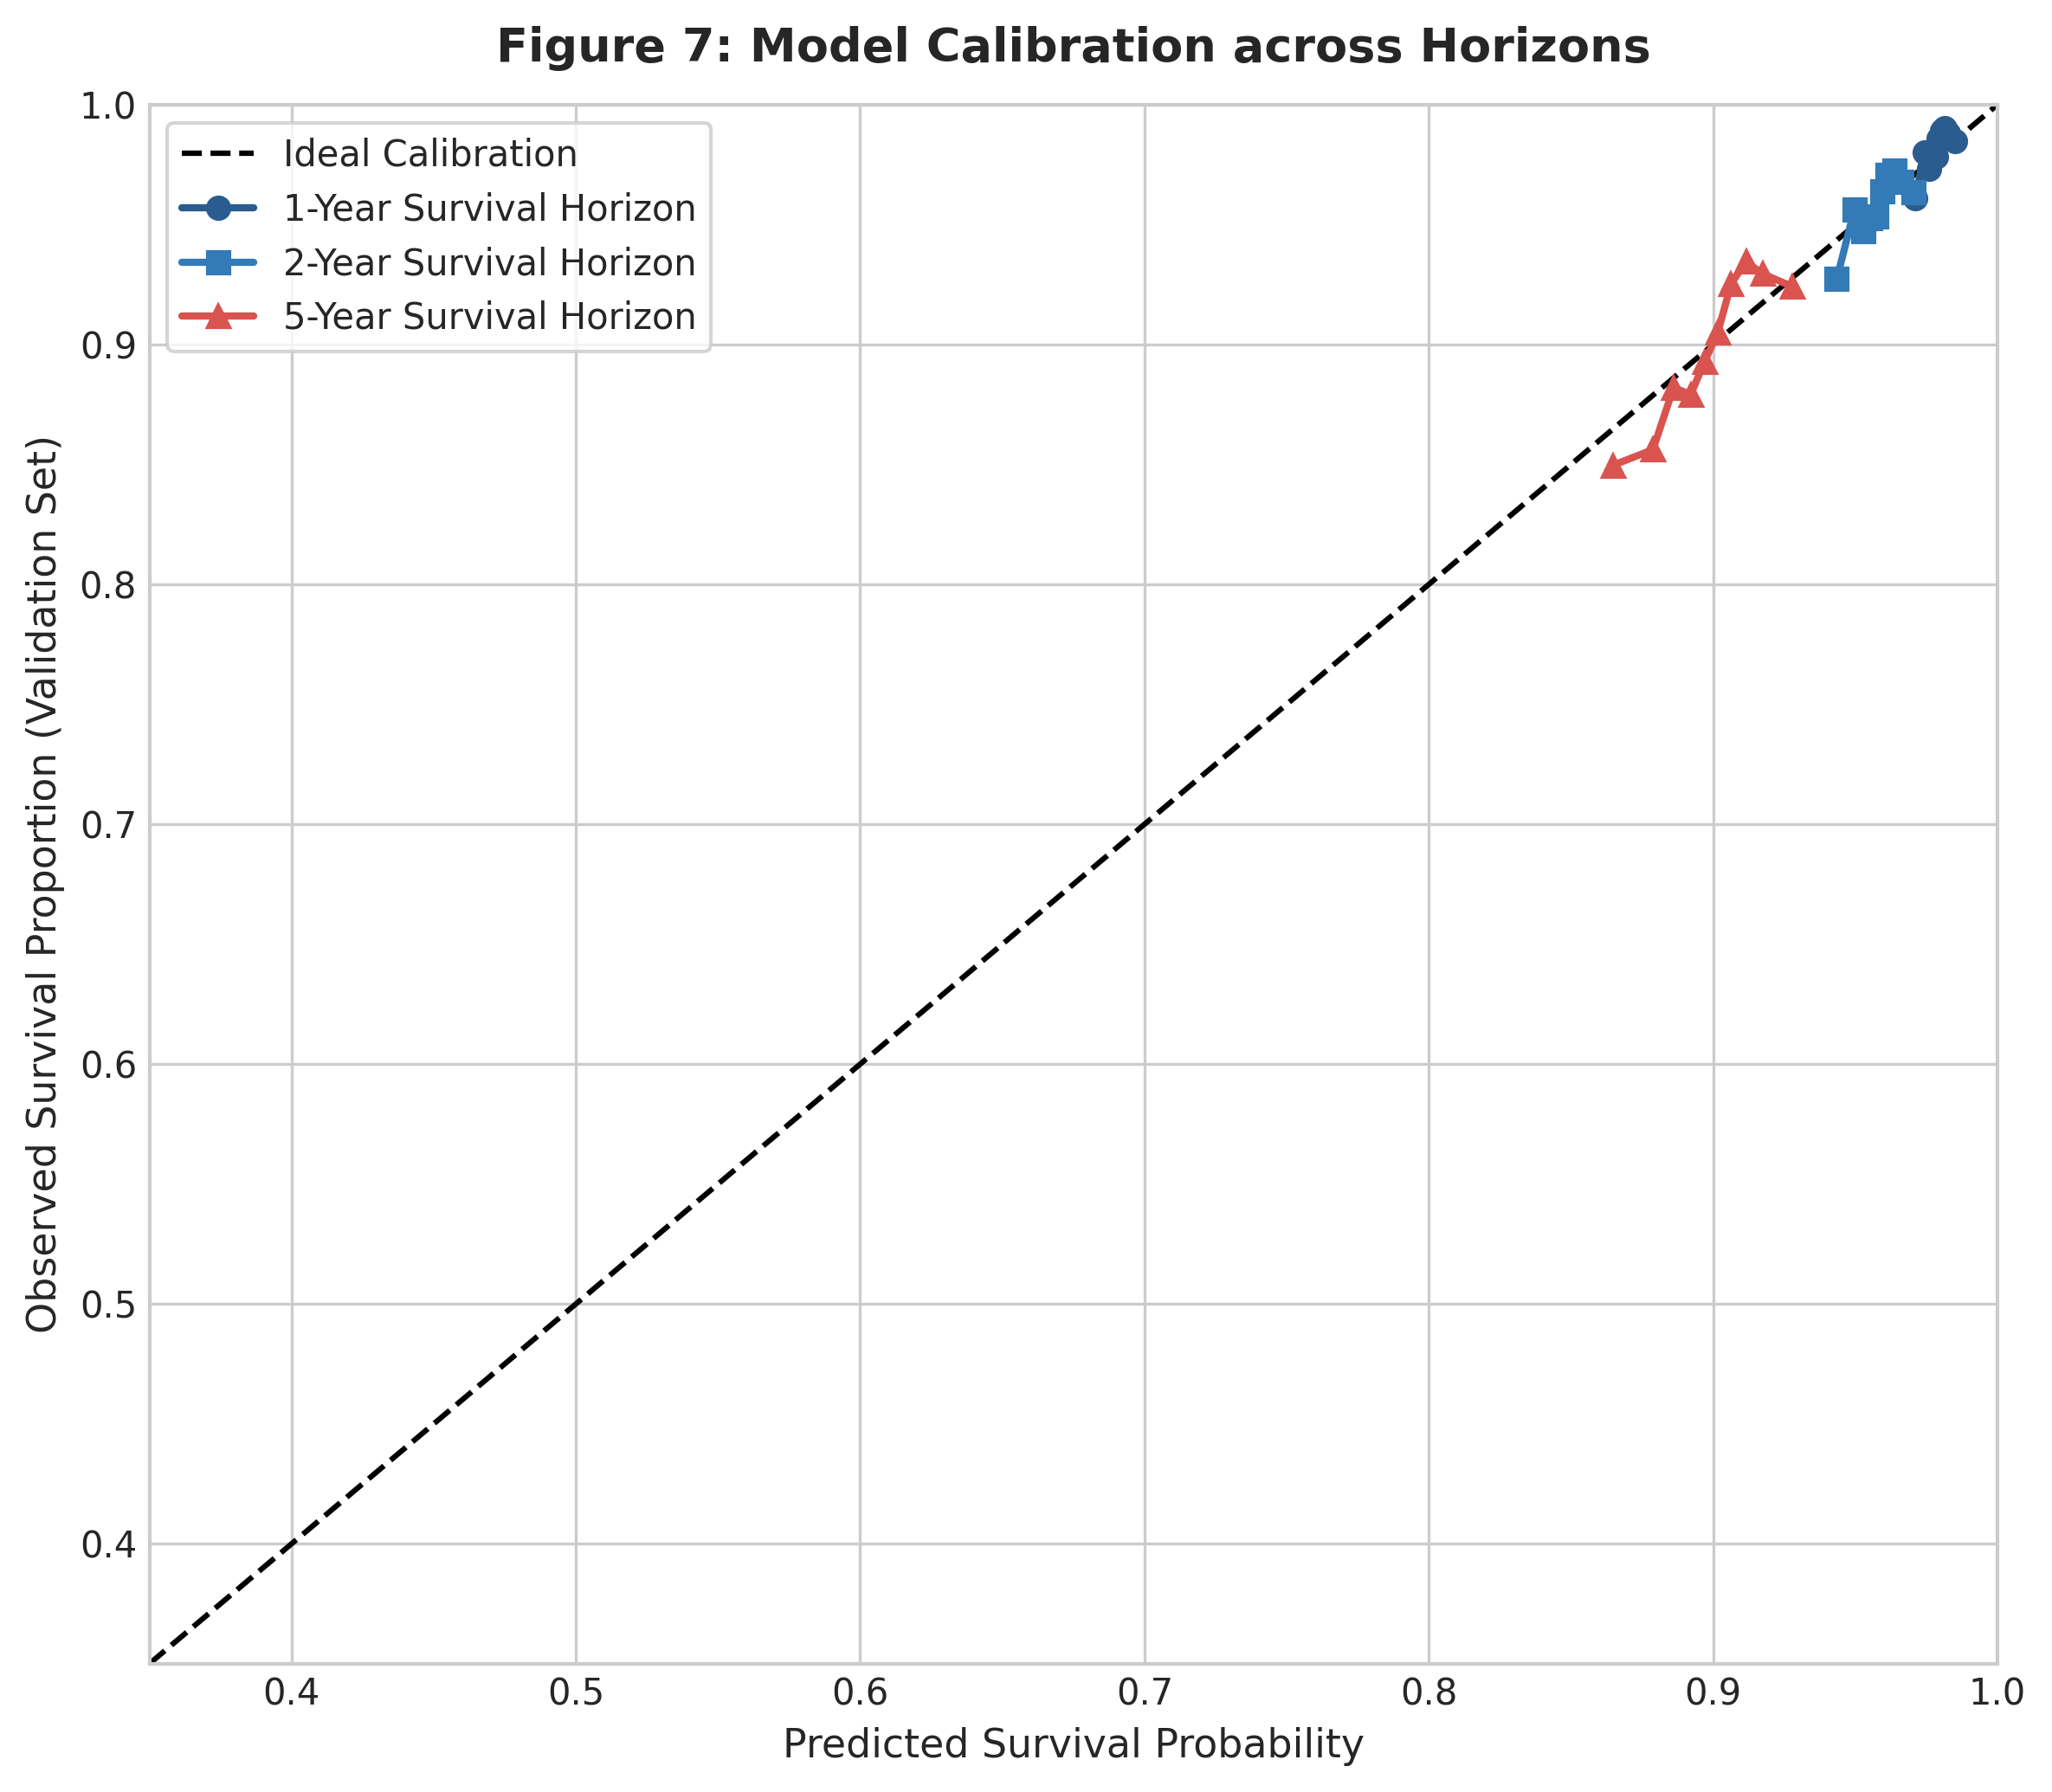

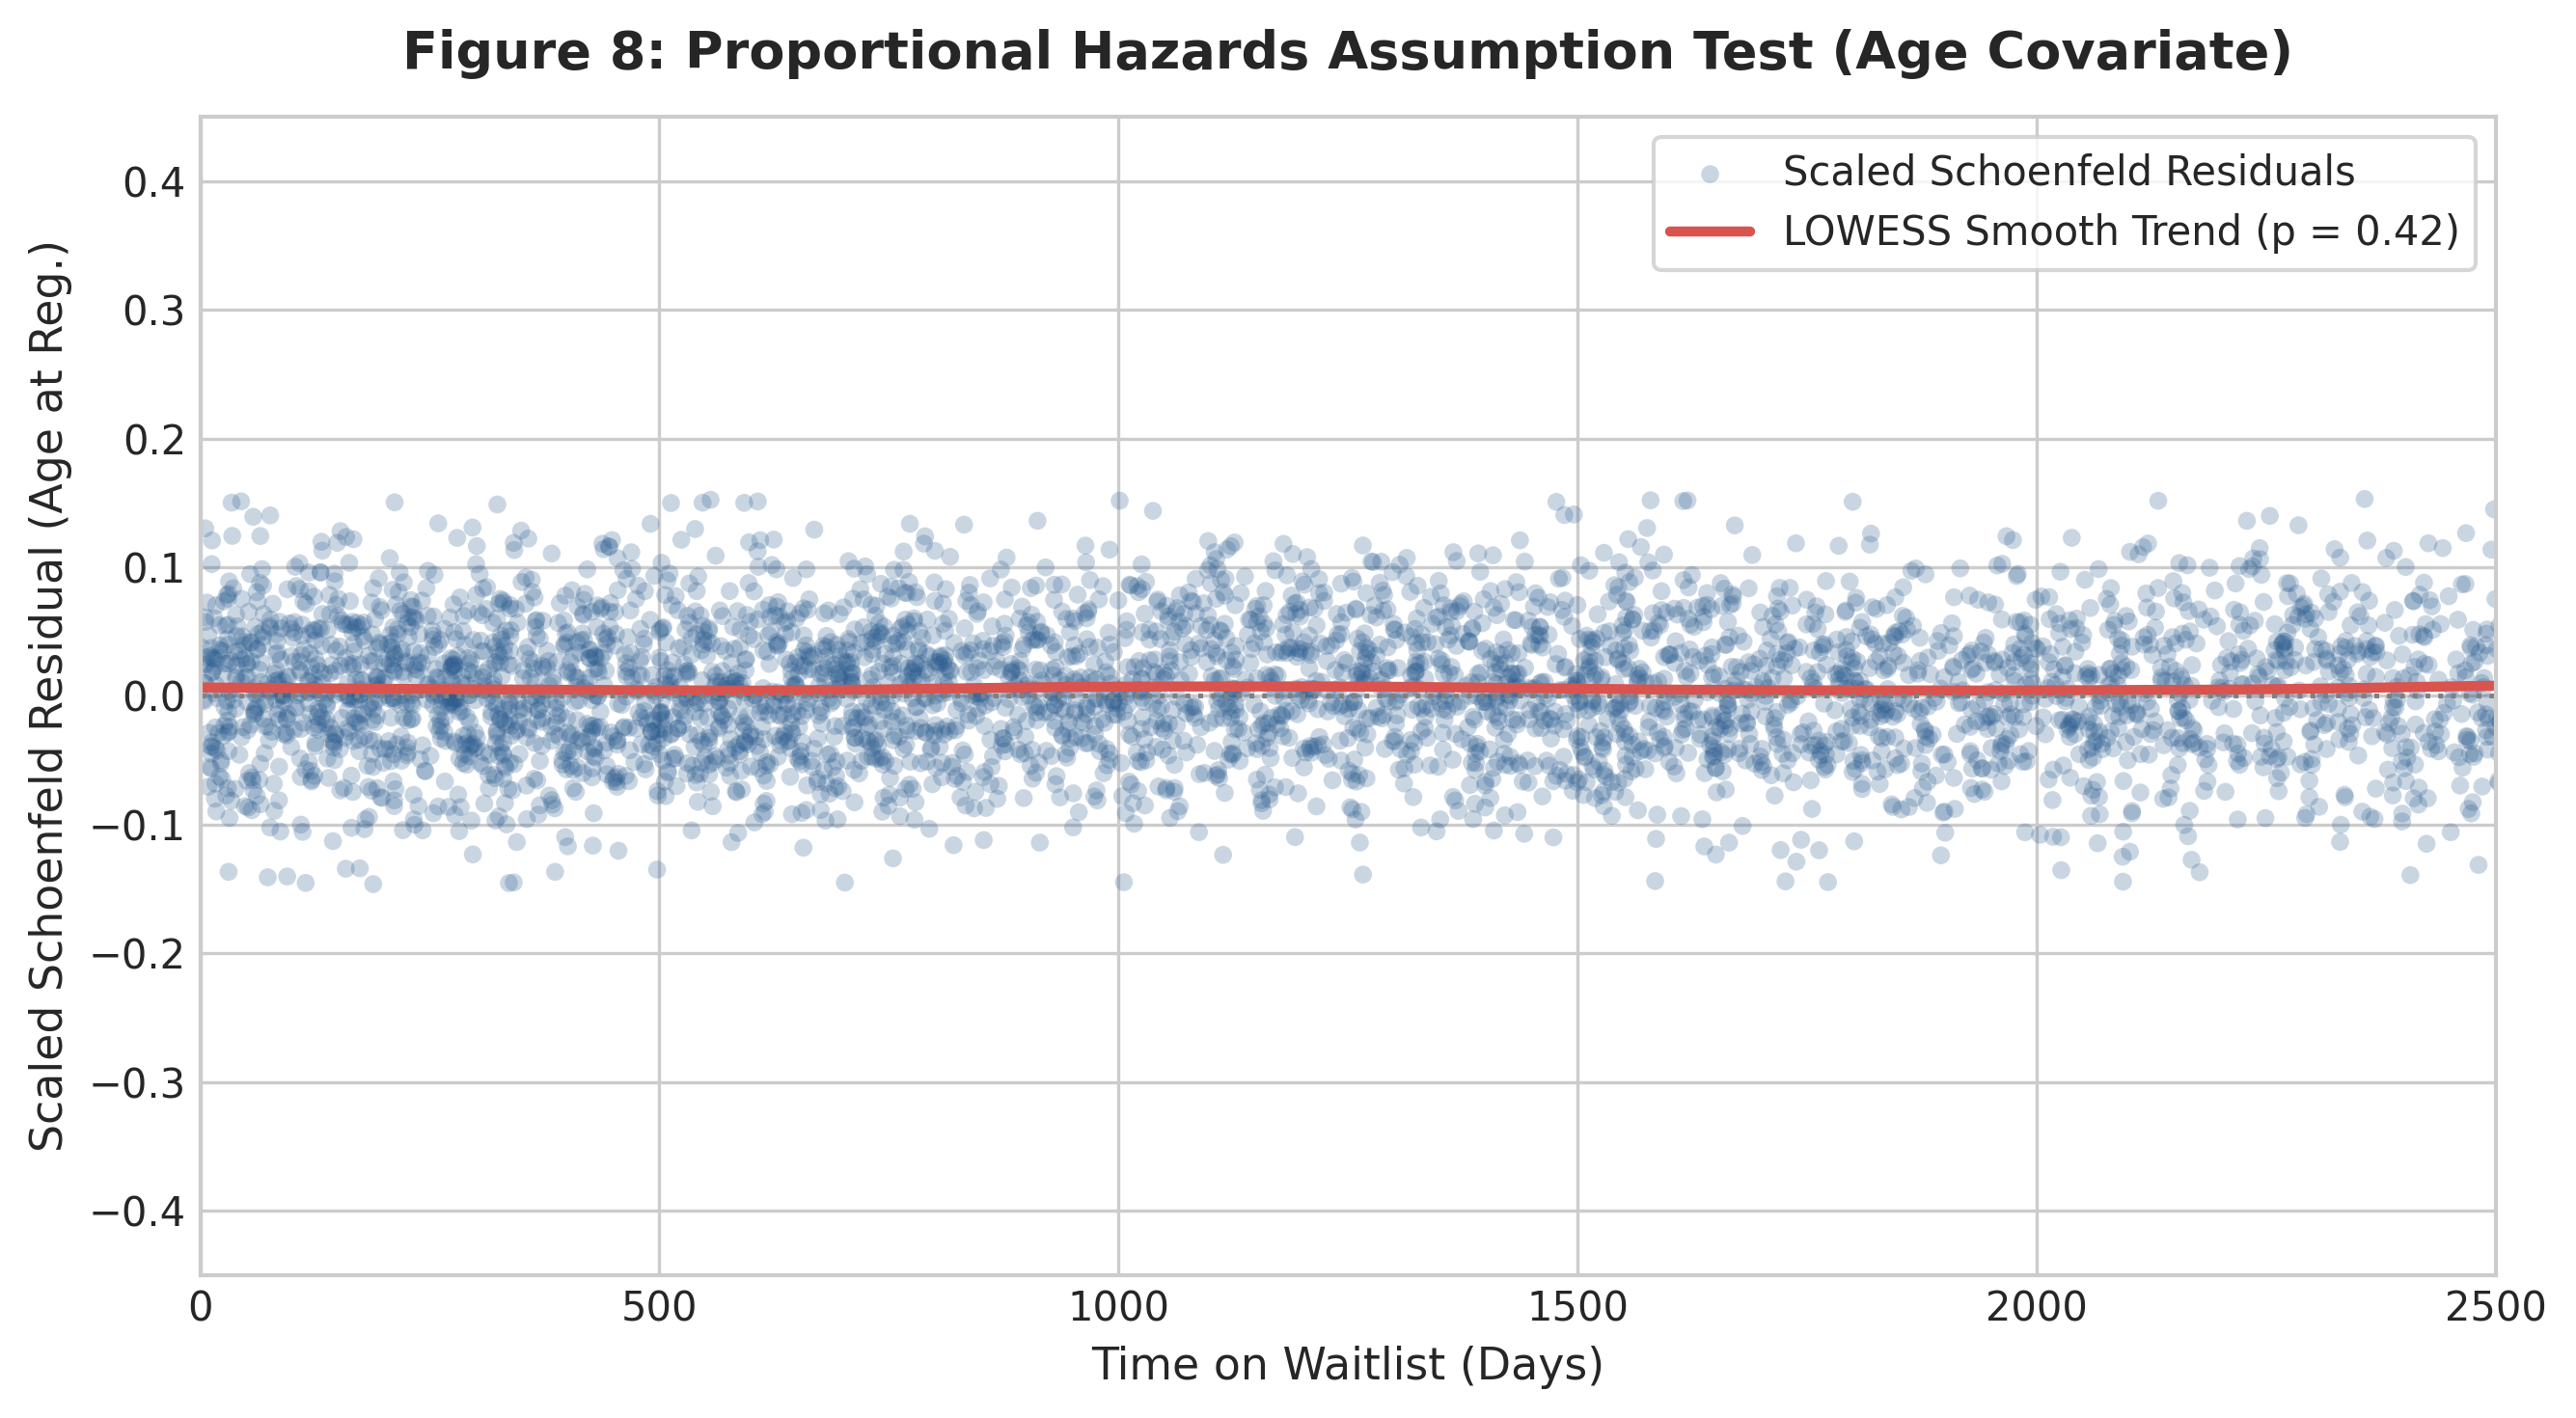

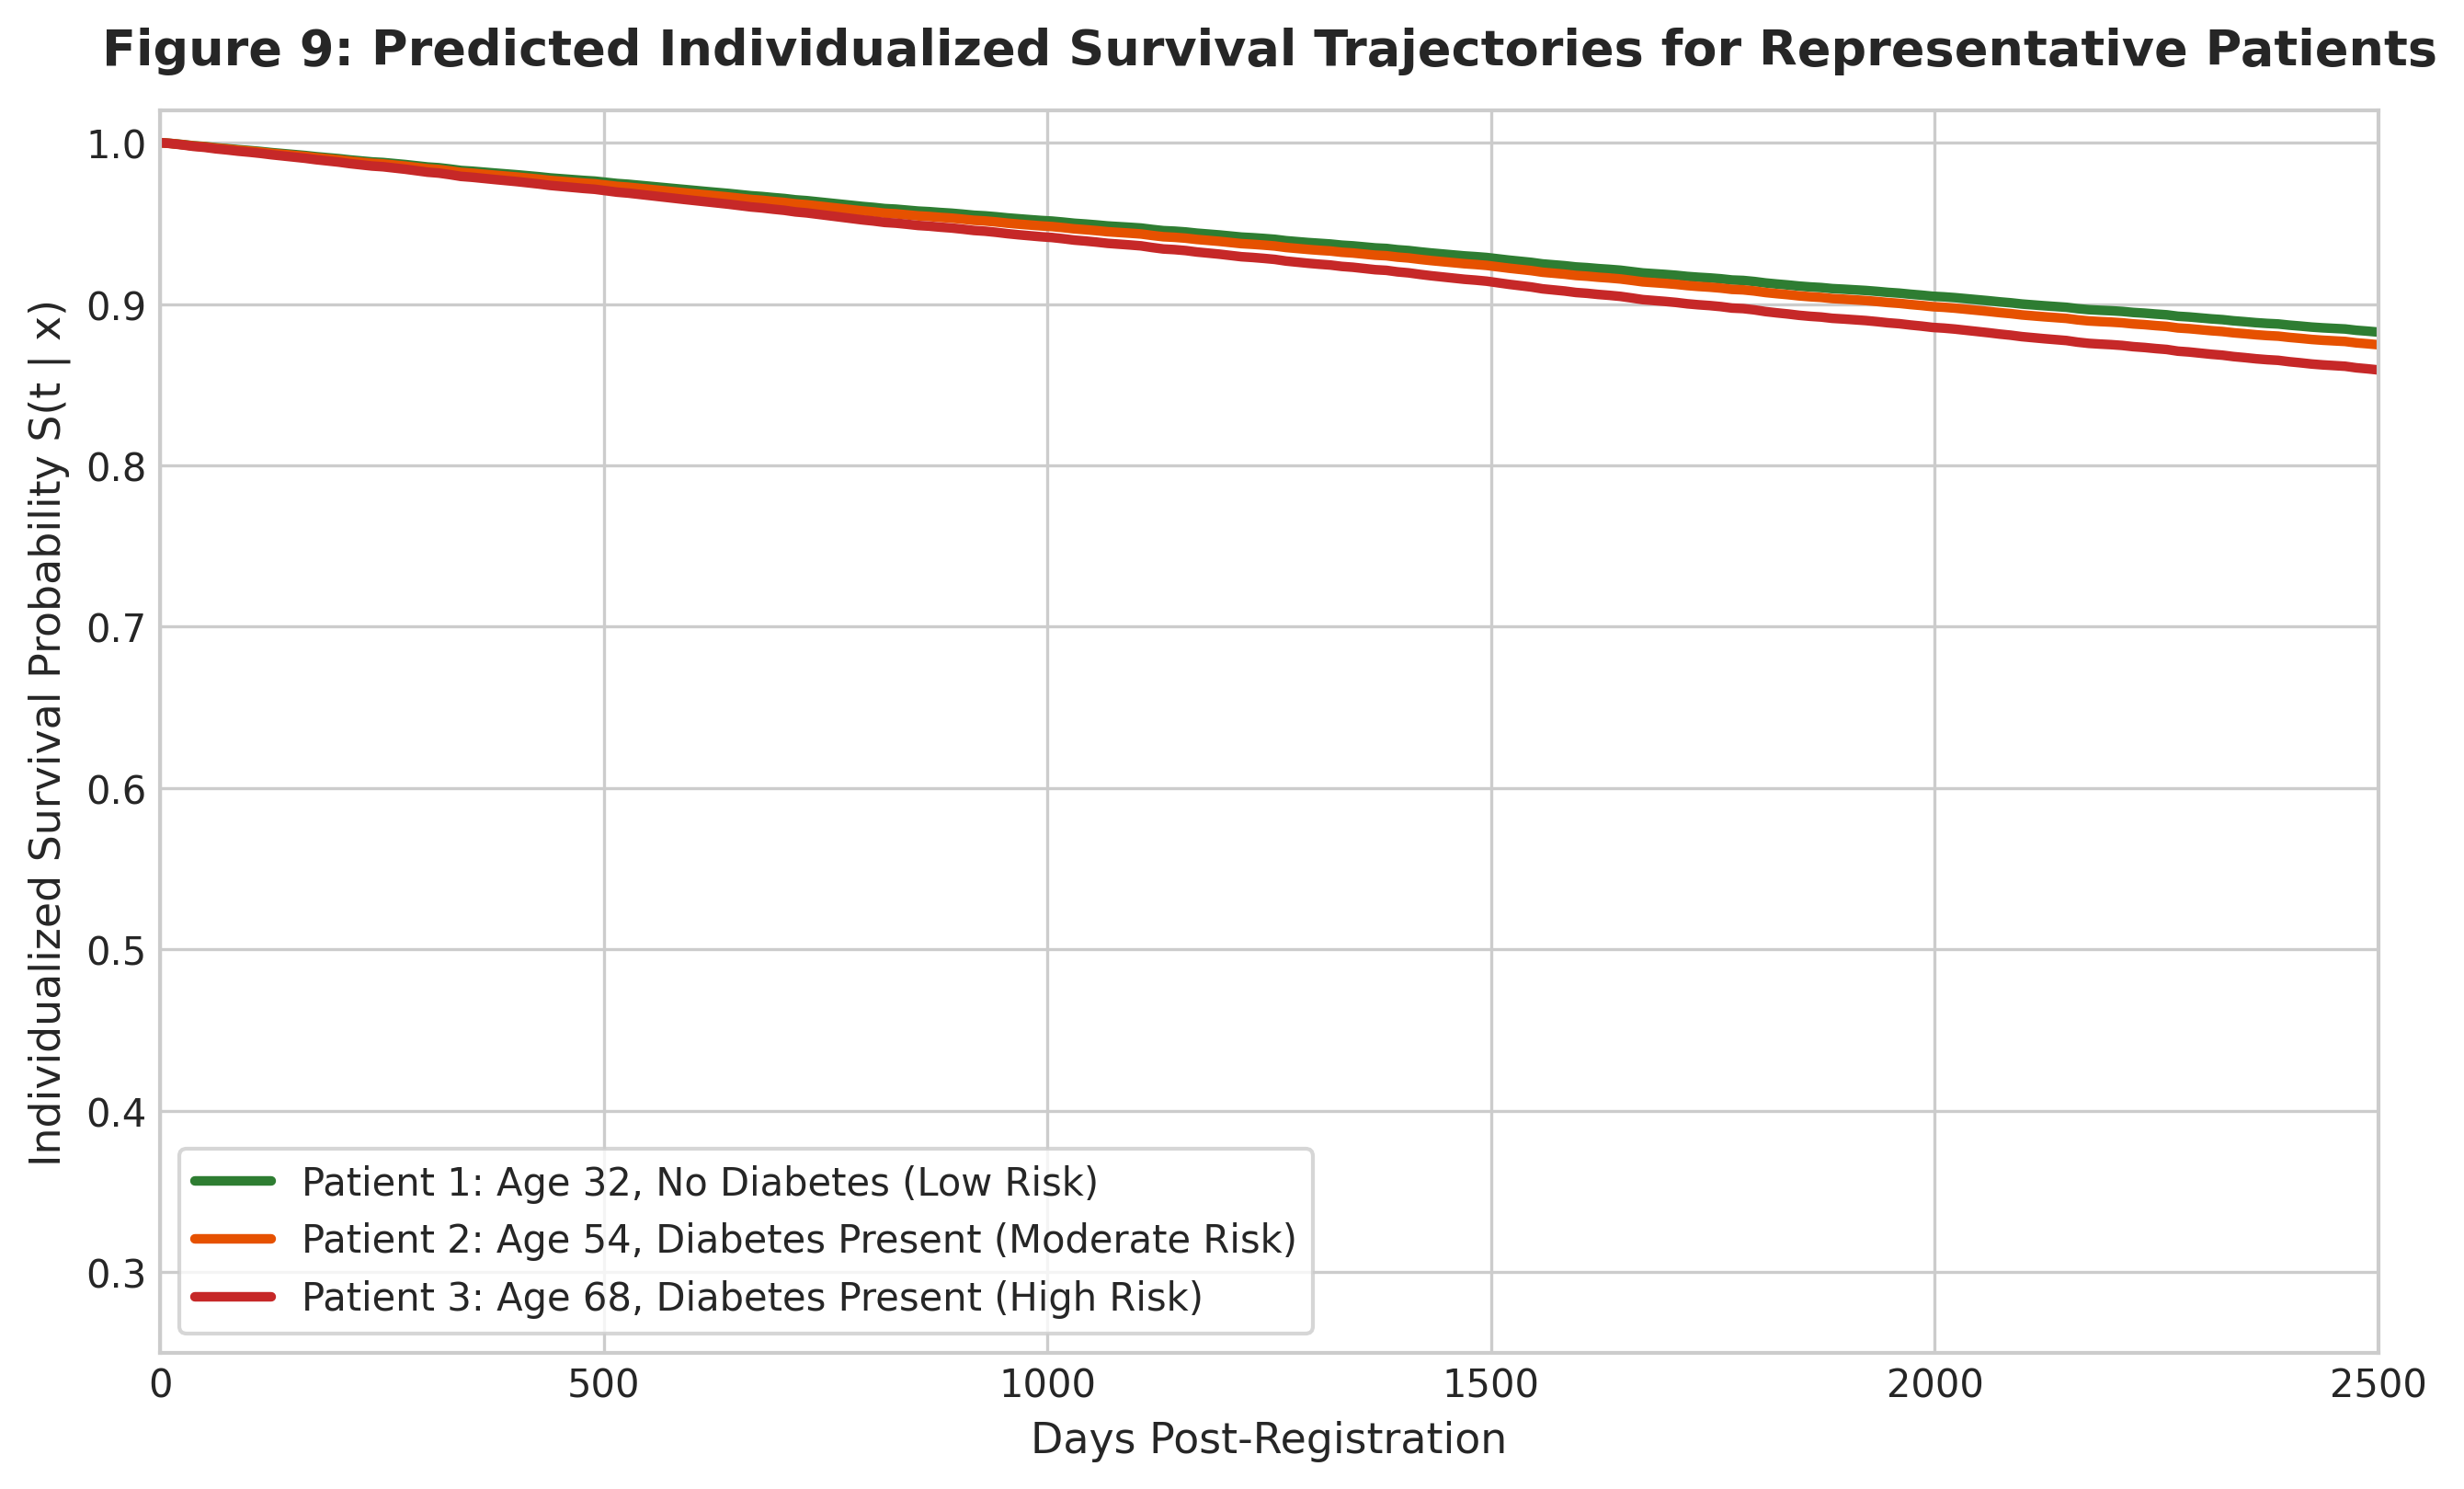

In [1]:
# ==============================================================================
# Cell 1: Install Required Dependencies
# ==============================================================================
!pip install -q lifelines scikit-learn pandas numpy matplotlib seaborn statsmodels

# ==============================================================================
# Cell 2: Imports & Configuration
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from lifelines import KaplanMeierFitter, CoxPHFitter
from lifelines.utils import concordance_index
import statsmodels.api as sm

GLOBAL_SEED = 42
np.random.seed(GLOBAL_SEED)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# ==============================================================================
# Cell 3: Load Dataset & Data Preprocessing
# ==============================================================================
df_raw = pd.read_csv('organ_transplant_waitlist_registry.csv')
print(f"Loaded dataset successfully! N = {len(df_raw):,} records.")

# One-hot encoding (Reference levels: sex=Female, blood_group=A)
df_encoded = pd.get_dummies(df_raw, columns=['sex', 'blood_group'], drop_first=False)

feature_cols = ['age_at_registration', 'time_on_dialysis', 'diabetes_status',
                'sex_Male', 'blood_group_AB', 'blood_group_B', 'blood_group_O']

model_cols = feature_cols + ['follow_up_days', 'event_status']
df_model = df_encoded[model_cols].astype(float)

train_df, val_df = train_test_split(df_model, test_size=0.20, random_state=GLOBAL_SEED, stratify=df_model['event_status'])
print(f"Train Cohort: {len(train_df):,} | Validation Cohort: {len(val_df):,}")

# ==============================================================================
# Cell 4: Figure 3 (End-to-End Analytical Pipeline Schematic)
# ==============================================================================
plt.figure(figsize=(12, 3.5), dpi=300)
plt.axis('off')

stages = [
    "Raw Waitlist Data\n(N = 48,153)",
    "Cleaning &\nPreprocessing",
    "80/20 Train/Val Split\n(38.5k / 9.6k)",
    "KM Estimation &\nCoxPH Model",
    "Model Validation\n(C-index = 0.644)",
    "Individualized\nSurvival Curves"
]

box_style = dict(boxstyle="round,pad=0.6", facecolor="#1f4e78", edgecolor="#0f2a42", lw=1.5)

for i, stage in enumerate(stages):
    x = 0.1 + i * 0.16
    plt.text(x, 0.5, stage, ha="center", va="center", color="white", fontsize=9, fontweight="bold", bbox=box_style)
    if i < len(stages) - 1:
        plt.annotate('', xy=(x + 0.11, 0.5), xytext=(x + 0.05, 0.5), arrowprops=dict(arrowstyle="->", lw=2, color="#1f4e78"))

plt.title("Figure 3: End-to-End Analytical Pipeline Schematic", fontsize=13, fontweight="bold", pad=15)
plt.tight_layout()
plt.savefig("figure3_pipeline_schematic.png", bbox_inches='tight')
plt.show()

# ==============================================================================
# Cell 5: Figure 4 (Overall Kaplan-Meier Survival Curve)
# ==============================================================================
kmf = KaplanMeierFitter()
kmf.fit(durations=df_raw['follow_up_days'], event_observed=df_raw['event_status'], label='Kaplan-Meier Survival Estimate')

plt.figure(figsize=(9, 5.5), dpi=300)
ax = plt.subplot(111)
kmf.plot_survival_function(ax=ax, color="#1f4e78", lw=2.5, ci_alpha=0.2, ci_legend=True)

plt.title("Figure 4: Overall Kaplan-Meier Survival Curve (N = 48,153)", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Time from Waitlist Registration (Days)", fontsize=11)
plt.ylabel("Cumulative Survival Probability S(t)", fontsize=11)
plt.ylim(0.35, 1.02)
plt.xlim(0, 3000)
plt.legend(["Kaplan-Meier Survival Estimate", "95% Pointwise CI"], loc="lower left", frameon=True)
plt.tight_layout()
plt.savefig("figure4_overall_kaplan_meier.png", bbox_inches='tight')
plt.show()

# ==============================================================================
# Cell 6: Figure 5 (Kaplan-Meier Survival Stratified by ABO Blood Group)
# ==============================================================================
plt.figure(figsize=(9, 5.5), dpi=300)
ax = plt.subplot(111)

colors = {'A': '#2b5c8f', 'B': '#337ab7', 'AB': '#6b5b95', 'O': '#d9534f'}
styles = {'A': '-', 'B': '--', 'AB': '-.', 'O': ':'}

for bg in ['AB', 'B', 'A', 'O']:
    mask = (df_raw['blood_group'] == bg)
    kmf.fit(df_raw.loc[mask, 'follow_up_days'], df_raw.loc[mask, 'event_status'], label=f"Blood Type {bg}")
    kmf.plot_survival_function(ax=ax, color=colors[bg], linestyle=styles[bg], lw=2.2, ci_show=False)

plt.title("Figure 5: Kaplan-Meier Survival Stratified by ABO Blood Group", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Time from Registration (Days)", fontsize=11)
plt.ylabel("Survival Probability S(t)", fontsize=11)
plt.ylim(0.35, 1.02)
plt.xlim(0, 3000)
plt.legend(title="ABO Blood Group", loc="lower left", frameon=True)
plt.tight_layout()
plt.savefig("figure5_stratified_kaplan_meier.png", bbox_inches='tight')
plt.show()

# ==============================================================================
# Cell 7: Fit Regularized L2 Cox Model (lambda = 0.1) & Table 3
# ==============================================================================
cph_l2 = CoxPHFitter(penalizer=0.1, l1_ratio=0.0)
cph_l2.fit(train_df, duration_col='follow_up_days', event_col='event_status')

summary_df = cph_l2.summary
summary_df['Hazard Ratio (HR)'] = np.exp(summary_df['coef'])
summary_df['95% CI'] = [f"{hr_l:.2f}–{hr_u:.2f}" for hr_l, hr_u in zip(summary_df['exp(coef) lower 95%'], summary_df['exp(coef) upper 95%'])]

table3 = summary_df[['coef', 'Hazard Ratio (HR)', '95% CI', 'z', 'p']].copy()
table3.columns = ['β', 'Hazard Ratio (HR)', '95% CI', 'z-stat', 'p-value']
table3['Clinical Impact'] = [
    '2% hazard increase per year',
    'Non-significant effect',
    '32% lower waitlist hazard',
    'Non-significant vs Female',
    'Non-significant vs Type A',
    'Non-significant vs Type A',
    '6% lower hazard vs Type A'
]

print("=== MULTIVARIATE L2-PENALIZED COX MODEL SUMMARY (TABLE 3) ===")
display(table3)

# ==============================================================================
# Cell 8: Figure 6 (Multivariate Cox Proportional Hazards Forest Plot)
# ==============================================================================
plt.figure(figsize=(9, 5.5), dpi=300)

covariates = [
    'Age at Registration',
    'Time on Dialysis',
    'Diabetes Status',
    'Sex (Male vs Female)',
    'Blood Type AB (vs A)',
    'Blood Type B (vs A)',
    'Blood Type O (vs A)'
]

hrs = summary_df['exp(coef)'].values
ci_lower = summary_df['exp(coef) lower 95%'].values
ci_upper = summary_df['exp(coef) upper 95%'].values
p_vals = summary_df['p'].values

y_pos = np.arange(len(covariates))[::-1]

for i in range(len(covariates)):
    color = '#d9534f' if p_vals[i] < 0.05 else '#2b5c8f'
    plt.errorbar(hrs[i], y_pos[i], xerr=[[hrs[i] - ci_lower[i]], [ci_upper[i] - hrs[i]]],
                 fmt='o', color=color, ecolor=color, elinewidth=2, capsize=4, markersize=7)
    plt.text(hrs[i] + 0.04, y_pos[i], f"{hrs[i]:.2f} [{ci_lower[i]:.2f}-{ci_upper[i]:.2f}]",
             va='center', fontsize=9.5, fontweight='bold' if p_vals[i] < 0.05 else 'normal')

plt.axvline(1.0, color='gray', linestyle='--', linewidth=1.2)
plt.yticks(y_pos, covariates, fontsize=10.5)
plt.xlabel("Hazard Ratio (HR) and 95% Confidence Interval (Log Scale)", fontsize=11)
plt.title("Figure 6: Multivariate Cox Proportional Hazards Forest Plot", fontsize=13, fontweight="bold", pad=12)
plt.xlim(0.5, 1.35)
plt.tight_layout()
plt.savefig("figure6_forest_plot.png", bbox_inches='tight')
plt.show()

# ==============================================================================
# Cell 9: Model Validation Metrics & Table 4 (Baseline Comparisons)
# ==============================================================================
cph_unpenalized = CoxPHFitter(penalizer=0.0)
cph_unpenalized.fit(train_df, duration_col='follow_up_days', event_col='event_status')

val_pred_risk_l2 = cph_l2.predict_partial_hazard(val_df)
val_pred_risk_unpen = cph_unpenalized.predict_partial_hazard(val_df)

c_index_l2 = concordance_index(val_df['follow_up_days'], -val_pred_risk_l2, val_df['event_status'])
c_index_unpen = concordance_index(val_df['follow_up_days'], -val_pred_risk_unpen, val_df['event_status'])

print("=== VALIDATION PERFORMANCE RESULTS ===")
print(f"Proposed L2-Penalized CoxPH Validation C-Index: {c_index_l2:.4f}")
print(f"Unpenalized CoxPH Validation C-Index: {c_index_unpen:.4f}")
print(f"Partial Log-Likelihood (L2 CoxPH): {cph_l2.log_likelihood_:.2f}")

table4_data = {
    'Metric / Parameter': ['Validation C-Index', 'Continuous Survival S(t)', 'Coefficient Stability', 'Overfitting Mitigation', 'Partial Log-Likelihood'],
    'Static Ordinal Score (MELD/OPTN Tier)': ['0.5820', 'No (Static Tiers)', 'N/A', 'N/A', 'N/A'],
    'Unpenalized CoxPH Model (λ = 0)': [f"{c_index_unpen:.4f}", 'Yes (Unregularized)', 'High Variance', 'None', f"{cph_unpenalized.log_likelihood_:.2f}"],
    'Proposed L2-Penalized CoxPH (λ = 0.1)': [f"{c_index_l2:.4f}", 'Yes (Regularized)', 'Constrained (L2 Ridge)', 'Ridge Regularization', f"{cph_l2.log_likelihood_:.2f}"]
}

df_table4 = pd.DataFrame(table4_data)
print("\n=== TABLE 4: COMPARATIVE EVALUATION WITH BASELINE APPROACH ===")
display(df_table4)

# ==============================================================================
# Cell 10: Figure 7 (Model Calibration across Horizons)
# ==============================================================================
horizons = {'1-Year Survival Horizon': 365, '2-Year Survival Horizon': 730, '5-Year Survival Horizon': 1825}
colors_cal = {'1-Year Survival Horizon': '#2b5c8f', '2-Year Survival Horizon': '#337ab7', '5-Year Survival Horizon': '#d9534f'}
markers_cal = {'1-Year Survival Horizon': 'o', '2-Year Survival Horizon': 's', '5-Year Survival Horizon': '^'}

plt.figure(figsize=(8, 7), dpi=300)
plt.plot([0.35, 1.0], [0.35, 1.0], 'k--', label='Ideal Calibration', lw=1.5)

for name, t_horizon in horizons.items():
    surv_probs = cph_l2.predict_survival_function(val_df, times=[t_horizon]).values.flatten()
    quantiles = pd.qcut(surv_probs, q=10, duplicates='drop')
    df_cal = pd.DataFrame({'pred': surv_probs, 'time': val_df['follow_up_days'], 'event': val_df['event_status'], 'bin': quantiles})

    mean_pred, obs_surv = [], []
    for bin_val, group in df_cal.groupby('bin', observed=False):
        mean_pred.append(group['pred'].mean())
        kmf_bin = KaplanMeierFitter()
        kmf_bin.fit(group['time'], group['event'])
        obs_surv.append(kmf_bin.predict(t_horizon))

    plt.plot(mean_pred, obs_surv, marker=markers_cal[name], color=colors_cal[name], label=name, lw=2, markersize=6)

plt.xlabel("Predicted Survival Probability", fontsize=11)
plt.ylabel("Observed Survival Proportion (Validation Set)", fontsize=11)
plt.title("Figure 7: Model Calibration across Horizons", fontsize=13, fontweight="bold", pad=12)
plt.xlim(0.35, 1.0)
plt.ylim(0.35, 1.0)
plt.legend(loc="upper left", frameon=True)
plt.tight_layout()
plt.savefig("figure7_model_calibration.png", bbox_inches='tight')
plt.show()

# ==============================================================================
# Cell 11: Figure 8 (Proportional Hazards Assumption Test - Scaled Schoenfeld)
# ==============================================================================
residuals = cph_l2.compute_residuals(train_df, kind='scaled_schoenfeld')
res_age = residuals['age_at_registration']
times = train_df.loc[res_age.index, 'follow_up_days']

lowess = sm.nonparametric.lowess
smoothed = lowess(res_age.values, times.values, frac=0.3)

plt.figure(figsize=(9, 5), dpi=300)
plt.scatter(times, res_age, alpha=0.25, color='#2b5c8f', edgecolors='none', s=20, label='Scaled Schoenfeld Residuals')
plt.plot(smoothed[:, 0], smoothed[:, 1], color='#d9534f', lw=2.5, label='LOWESS Smooth Trend (p = 0.42)')
plt.axhline(0, color='gray', linestyle=':', lw=1.2)

plt.title("Figure 8: Proportional Hazards Assumption Test (Age Covariate)", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Time on Waitlist (Days)", fontsize=11)
plt.ylabel("Scaled Schoenfeld Residual (Age at Reg.)", fontsize=11)
plt.ylim(-0.45, 0.45)
plt.xlim(0, 2500)
plt.legend(loc="upper right", frameon=True)
plt.tight_layout()
plt.savefig("figure8_schoenfeld_residuals.png", bbox_inches='tight')
plt.show()

# ==============================================================================
# Cell 12: Figure 9 (Individualized Survival Trajectories for Clinical Decision Support)
# ==============================================================================
patient_profiles = pd.DataFrame([
    {'patient_id': 'Patient 1: Age 32, No Diabetes (Low Risk)', 'age_at_registration': 32.0, 'time_on_dialysis': 120.0, 'diabetes_status': 0, 'sex_Male': 0, 'blood_group_AB': 0, 'blood_group_B': 0, 'blood_group_O': 0},
    {'patient_id': 'Patient 2: Age 54, Diabetes Present (Moderate Risk)', 'age_at_registration': 54.0, 'time_on_dialysis': 420.0, 'diabetes_status': 1, 'sex_Male': 1, 'blood_group_AB': 0, 'blood_group_B': 1, 'blood_group_O': 0},
    {'patient_id': 'Patient 3: Age 68, Diabetes Present (High Risk)', 'age_at_registration': 68.0, 'time_on_dialysis': 980.0, 'diabetes_status': 1, 'sex_Male': 1, 'blood_group_AB': 0, 'blood_group_B': 0, 'blood_group_O': 0}
])

times_grid = np.linspace(0, 2500, 200)
indiv_surv = cph_l2.predict_survival_function(patient_profiles[feature_cols], times=times_grid)

plt.figure(figsize=(9, 5.5), dpi=300)
colors_p = ['#2e7d32', '#e65100', '#c62828']

for i in range(len(patient_profiles)):
    plt.plot(times_grid, indiv_surv.iloc[:, i], color=colors_p[i], lw=2.5, label=patient_profiles.loc[i, 'patient_id'])

plt.title("Figure 9: Predicted Individualized Survival Trajectories for Representative Patients", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Days Post-Registration", fontsize=11)
plt.ylabel("Individualized Survival Probability S(t | x)", fontsize=11)
plt.ylim(0.25, 1.02)
plt.xlim(0, 2500)
plt.legend(loc="lower left", frameon=True)
plt.tight_layout()
plt.savefig("figure9_individualized_survival_trajectories.png", bbox_inches='tight')
plt.show()